# 14.4. 물 분자의 분자 오비탈

In [1]:
import numpy as np

a_O2s, a_O2p, a_H = -32.38, -15.85, -13.6
b_s, b_p = -4.0, -5.0


def water_blocks(angle):
    half = np.radians(angle) / 2
    H_A1 = np.array(
        [
            [a_O2s, 0.0, np.sqrt(2) * b_s],
            [0.0, a_O2p, np.sqrt(2) * b_p * np.cos(half)],
            [np.sqrt(2) * b_s, np.sqrt(2) * b_p * np.cos(half), a_H],
        ]
    )
    H_B2 = np.array(
        [
            [a_O2p, np.sqrt(2) * b_p * np.sin(half)],
            [np.sqrt(2) * b_p * np.sin(half), a_H],
        ]
    )
    H_B1 = np.array([[a_O2p]])
    return {"a1": H_A1, "b2": H_B2, "b1": H_B1}


first = {"a1": 2, "b2": 1, "b1": 1}

levels = []
for sym, H in water_blocks(104.5).items():
    E, C = np.linalg.eigh(H)
    for i in range(len(E)):
        w_H = C[-1, i] ** 2 if sym != "b1" else 0.0
        levels.append((E[i], f"{first[sym] + i}{sym}", w_H))
levels.sort()

IE = {"2a1": 32.2, "1b2": 18.5, "3a1": 14.7, "1b1": 12.6}


n = 8
print(f"{'MO':>4} {'E (eV)':>8} {'H weight':>9} {'e':>3} {'IE (eV)':>9}")
for E, name, w_H in levels:
    k = min(n, 2)
    n -= k
    ie = f"{IE[name]:9.1f}" if name in IE else f"{'':>9}"
    print(f"{name:>4} {E:8.2f} {w_H:9.1%} {k:3d} {ie}")

  MO   E (eV)  H weight   e   IE (eV)
 2a1   -34.03      7.8%   2      32.2
 1b2   -20.43     40.1%   2      18.5
 3a1   -18.47     25.6%   2      14.7
 1b1   -15.85      0.0%   2      12.6
 4a1    -9.33     66.6%   0          
 2b2    -9.02     59.9%   0          


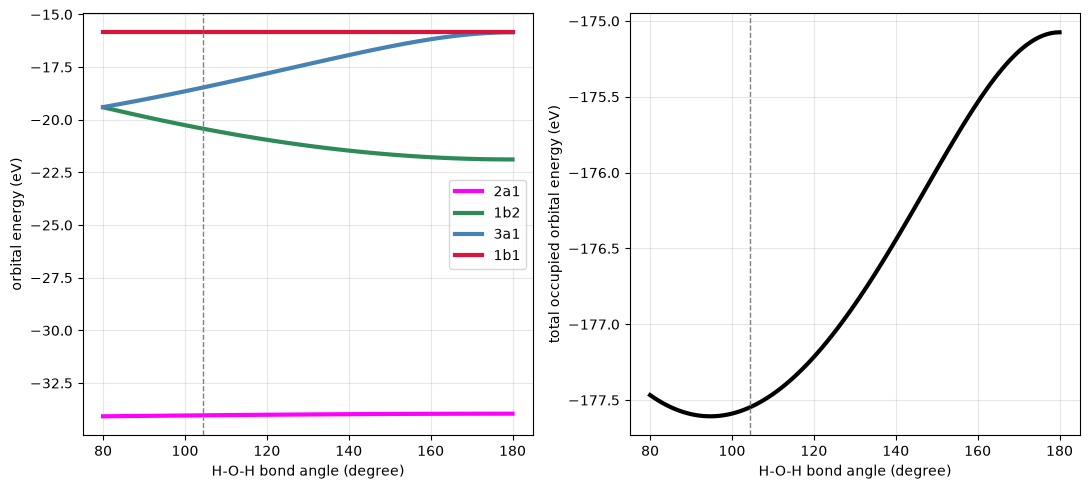

In [2]:
import matplotlib.pyplot as plt

angles = np.arange(80, 181, 1)
energies = {"2a1": [], "1b2": [], "3a1": [], "1b1": []}
total = []
for theta in angles:
    blocks = water_blocks(theta)
    E_a1 = np.linalg.eigvalsh(blocks["a1"])
    E_b2 = np.linalg.eigvalsh(blocks["b2"])
    E_b1 = np.linalg.eigvalsh(blocks["b1"])
    occ = {"2a1": E_a1[0], "1b2": E_b2[0], "3a1": E_a1[1], "1b1": E_b1[0]}
    for mo in energies:
        energies[mo].append(occ[mo])
    total.append(2 * sum(occ.values()))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
for mo, col in [("2a1", "magenta"), ("1b2", "seagreen"), ("3a1", "steelblue"), ("1b1", "crimson")]:
    ax.plot(angles, energies[mo], lw=3, color=col, label=mo)
ax.axvline(104.5, color="gray", ls="--", lw=1)
ax.set_xlabel("H-O-H bond angle (degree)")
ax.set_ylabel("orbital energy (eV)")
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(angles, total, lw=3, color="black")
ax.axvline(104.5, color="gray", ls="--", lw=1)
ax.set_xlabel("H-O-H bond angle (degree)")
ax.set_ylabel("total occupied orbital energy (eV)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()